In [4]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.circuit import QuantumCircuit
from qiskit import transpile

qc = QuantumCircuit(1, 1)
qc.x(0)
qc.measure(0, 0)

# Build noise model
noise_model = NoiseModel()
error = depolarizing_error(0.75, 1)
noise_model.add_all_qubit_quantum_error(
    error, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# Noiseless
sim_ideal = AerSimulator()
result_ideal = sim_ideal.run(transpile(qc, sim_ideal), shots=1024).result()
print("Noiseless     :", result_ideal.get_counts())

# Noisy
sim_noisy = AerSimulator(noise_model=noise_model)
result_noisy = sim_noisy.run(transpile(qc, sim_noisy), shots=1024).result()
print("Noisy p=0.75  :", result_noisy.get_counts())

Noiseless     : {'1': 1024}
Noisy p=0.75  : {'1': 649, '0': 375}


In [5]:
sim_check = AerSimulator()
qc_t = transpile(qc, sim_check)
print("Basis gates used:", qc_t.count_ops())

Basis gates used: OrderedDict({'x': 1, 'measure': 1})


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import json

from qiskit.circuit import QuantumCircuit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_algorithms import IterativeAmplitudeEstimation, EstimationProblem

print("All imports OK ✅")

All imports OK ✅


In [7]:
p_true = 0.3

class BernoulliA(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(theta_p, 0)

class BernoulliQ(QuantumCircuit):
    def __init__(self, probability):
        super().__init__(1)
        self._theta_p = 2 * np.arcsin(np.sqrt(probability))
        self.ry(2 * self._theta_p, 0)

    def power(self, k):
        q_k = QuantumCircuit(1)
        q_k.ry(2 * k * self._theta_p, 0)
        return q_k

problem = EstimationProblem(
    state_preparation=BernoulliA(p_true),
    grover_operator=BernoulliQ(p_true),
    objective_qubits=[0],
)
print("Problem defined ✅")

Problem defined ✅


In [8]:
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# Build noise model
noise_model_test = NoiseModel()
error_1q = depolarizing_error(0.75, 1)
noise_model_test.add_all_qubit_quantum_error(
    error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
)

# ── Clean baseline ──
sampler_clean = AerSampler(
    run_options={"shots": 1024}         # shots in run_options
)
iae_clean = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_clean
)
result_clean = iae_clean.estimate(problem)
print(f"p=0.00 | Estimate: {result_clean.estimation:.4f} | Queries: {result_clean.num_oracle_queries}")

# ── Noisy run ──
sampler_noisy = AerSampler(
    backend_options={"noise_model": noise_model_test},  # ✅ noise in backend_options
    run_options={"shots": 1024}                         # ✅ shots in run_options
)
iae_noisy = IterativeAmplitudeEstimation(
    epsilon_target=0.01, alpha=0.05, sampler=sampler_noisy
)
result_noisy = iae_noisy.estimate(problem)
print(f"p=0.75 | Estimate: {result_noisy.estimation:.4f} | Queries: {result_noisy.num_oracle_queries}")

# ── Difference check ──
diff = abs(result_clean.estimation - result_noisy.estimation)
print(f"\nDifference: {diff:.4f}")
if diff < 0.01:
    print("❌ Noise is NOT being applied!")
else:
    print("✅ Noise IS affecting the estimate!")

p=0.00 | Estimate: 0.3000 | Queries: 7168
p=0.75 | Estimate: 0.5077 | Queries: 4096

Difference: 0.2077
✅ Noise IS affecting the estimate!


In [48]:
import numpy as np
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════
# PARAMETERS — all defined here, nothing external
# ══════════════════════════════════════════════
N_REPEATS      = 30
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 40).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.6, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs}")

# ══════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════
def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": 1024}
        )
    else:
        sampler = AerSampler(run_options={"shots": 1024})
    return sampler

# ══════════════════════════════════════════════
# SWEEP
# ══════════════════════════════════════════════
sweep_results = []
run_count     = 0

for p_noise in noise_levels:
    print(f"\n--- Noise p = {p_noise:.5f} ---")
    sampler = build_noisy_sampler(p_noise)

    for eps in epsilon_values:
        estimates = []
        queries   = []

        for repeat in range(N_REPEATS):
            run_count += 1
            try:
                iae = IterativeAmplitudeEstimation(
                    epsilon_target=eps,
                    alpha=0.05,
                    sampler=sampler,
                )
                result = iae.estimate(problem)
                estimates.append(result.estimation)
                queries.append(result.num_oracle_queries)
            except Exception as e:
                estimates.append(0.0)
                queries.append(0)

        estimates   = np.array(estimates)
        rmse        = np.sqrt(np.mean((estimates - p_true) ** 2))
        avg_queries = np.mean(queries)
        collapsed   = rmse > eps

        individual_success = [
            1 if abs(est - p_true) <= eps else 0
            for est in estimates
        ]
        success_rate = np.mean(individual_success)

        sweep_results.append({
            "epsilon"     : eps,
            "noise"       : p_noise,
            "queries"     : avg_queries,
            "rmse"        : rmse,
            "collapsed"   : collapsed,
            "success_rate": success_rate,
        })

        print(f"  [Run {run_count}/{total_runs}] "
              f"eps={eps:.6f} | "
              f"Queries={avg_queries:>8.1f} | "
              f"RMSE={rmse:.5f} | "
              f"Success={success_rate:.2f} | "
              f"{'💀 FAILED' if collapsed else '✅ OK'}")

print(f"\n✅ Sweep complete — {total_runs} total runs")

Epsilon values    : 40 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.6000
Total combinations: 1640
Total IQAE runs   : 49200

--- Noise p = 0.00000 ---


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\3674684131.py:48: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [Run 30/49200] eps=0.000100 | Queries=1453363.2 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 60/49200] eps=0.000119 | Queries=1679940.3 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 90/49200] eps=0.000143 | Queries=1647342.9 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 120/49200] eps=0.000170 | Queries=1434555.7 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 150/49200] eps=0.000203 | Queries=933478.4 | RMSE=0.00002 | Success=1.00 | ✅ OK
  [Run 180/49200] eps=0.000242 | Queries=547054.9 | RMSE=0.00004 | Success=1.00 | ✅ OK
  [Run 210/49200] eps=0.000289 | Queries=593442.1 | RMSE=0.00004 | Success=1.00 | ✅ OK
  [Run 240/49200] eps=0.000346 | Queries=635904.0 | RMSE=0.00005 | Success=1.00 | ✅ OK
  [Run 270/49200] eps=0.000412 | Queries=214562.1 | RMSE=0.00322 | Success=0.97 | 💀 FAILED
  [Run 300/49200] eps=0.000492 | Queries= 95948.8 | RMSE=0.00010 | Success=1.00 | ✅ OK
  [Run 330/49200] eps=0.000588 | Queries=102195.2 | RMSE=0.00026 | Success=0.97 | ✅ OK
  [Run 360/49200] eps=0.000702 | Queri

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\3674684131.py:48: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [Run 1230/49200] eps=0.000100 | Queries=1560610.1 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 1260/49200] eps=0.000119 | Queries=1526272.0 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 1290/49200] eps=0.000143 | Queries=1603276.8 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 1320/49200] eps=0.000170 | Queries=1637649.1 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 1350/49200] eps=0.000203 | Queries=792371.2 | RMSE=0.00004 | Success=1.00 | ✅ OK
  [Run 1380/49200] eps=0.000242 | Queries=852787.2 | RMSE=0.00002 | Success=1.00 | ✅ OK
  [Run 1410/49200] eps=0.000289 | Queries=792780.8 | RMSE=0.00003 | Success=1.00 | ✅ OK
  [Run 1440/49200] eps=0.000346 | Queries=400520.5 | RMSE=0.00008 | Success=1.00 | ✅ OK
  [Run 1470/49200] eps=0.000412 | Queries=243336.5 | RMSE=0.00009 | Success=1.00 | ✅ OK
  [Run 1500/49200] eps=0.000492 | Queries= 94173.9 | RMSE=0.00009 | Success=1.00 | ✅ OK
  [Run 1530/49200] eps=0.000588 | Queries= 99396.3 | RMSE=0.00006 | Success=1.00 | ✅ OK
  [Run 1560/49200] eps=0.000

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\3674684131.py:48: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [Run 2430/49200] eps=0.000100 | Queries=1412676.3 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 2460/49200] eps=0.000119 | Queries=1403630.9 | RMSE=0.00014 | Success=0.97 | 💀 FAILED
  [Run 2490/49200] eps=0.000143 | Queries=1537194.7 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 2520/49200] eps=0.000170 | Queries=1486233.6 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 2550/49200] eps=0.000203 | Queries=806877.9 | RMSE=0.00003 | Success=1.00 | ✅ OK
  [Run 2580/49200] eps=0.000242 | Queries=869444.3 | RMSE=0.00003 | Success=1.00 | ✅ OK
  [Run 2610/49200] eps=0.000289 | Queries=770013.9 | RMSE=0.00006 | Success=1.00 | ✅ OK
  [Run 2640/49200] eps=0.000346 | Queries=442845.9 | RMSE=0.00006 | Success=1.00 | ✅ OK
  [Run 2670/49200] eps=0.000412 | Queries=146193.1 | RMSE=0.00011 | Success=1.00 | ✅ OK
  [Run 2700/49200] eps=0.000492 | Queries= 96836.3 | RMSE=0.00009 | Success=1.00 | ✅ OK
  [Run 2730/49200] eps=0.000588 | Queries= 95846.4 | RMSE=0.00011 | Success=1.00 | ✅ OK
  [Run 2760/49200] eps=0

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\3674684131.py:48: DeprecationWarning: Sampler has been deprecated as of Aer 0.15, please use SamplerV2 instead.
  sampler = build_noisy_sampler(p_noise)


  [Run 3630/49200] eps=0.000100 | Queries=1588394.7 | RMSE=0.00005 | Success=0.93 | ✅ OK
  [Run 3660/49200] eps=0.000119 | Queries=1505792.0 | RMSE=0.00078 | Success=0.80 | 💀 FAILED
  [Run 3690/49200] eps=0.000143 | Queries=1487394.1 | RMSE=0.00001 | Success=1.00 | ✅ OK
  [Run 3720/49200] eps=0.000170 | Queries=1474901.3 | RMSE=0.00124 | Success=0.93 | 💀 FAILED
  [Run 3750/49200] eps=0.000203 | Queries=934946.1 | RMSE=0.00004 | Success=1.00 | ✅ OK
  [Run 3780/49200] eps=0.000242 | Queries=846609.1 | RMSE=0.00045 | Success=0.93 | 💀 FAILED
  [Run 3810/49200] eps=0.000289 | Queries=876509.9 | RMSE=0.00110 | Success=0.90 | 💀 FAILED
  [Run 3840/49200] eps=0.000346 | Queries=339182.9 | RMSE=0.00052 | Success=0.97 | 💀 FAILED
  [Run 3870/49200] eps=0.000412 | Queries=150971.7 | RMSE=0.00074 | Success=0.93 | 💀 FAILED
  [Run 3900/49200] eps=0.000492 | Queries= 83353.6 | RMSE=0.00013 | Success=1.00 | ✅ OK
  [Run 3930/49200] eps=0.000588 | Queries= 95402.7 | RMSE=0.00089 | Success=0.93 | 💀 FAILED


KeyboardInterrupt: 

In [53]:
import numpy as np
from joblib import Parallel, delayed
from qiskit_aer.primitives import Sampler as AerSampler
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_algorithms import IterativeAmplitudeEstimation

# ══════════════════════════════════════════════
# PARAMETERS
# ══════════════════════════════════════════════
N_REPEATS      = 30
N_JOBS         = 18  # leave 2 threads free for system
epsilon_values = np.logspace(np.log10(0.0001), np.log10(0.1), 100).tolist()
noise_levels   = [0.0] + np.linspace(0.001, 0.4, 40).tolist()

total_combinations = len(epsilon_values) * len(noise_levels)
total_runs         = total_combinations * N_REPEATS

print(f"Epsilon values    : {len(epsilon_values)} | {min(epsilon_values):.6f} → {max(epsilon_values):.6f}")
print(f"Noise levels      : {len(noise_levels)}  | {min(noise_levels):.4f} → {max(noise_levels):.4f}")
print(f"Total combinations: {total_combinations}")
print(f"Total IQAE runs   : {total_runs}")
print(f"Running on        : {N_JOBS} parallel threads")

# ══════════════════════════════════════════════
# NOISE MODEL BUILDER
# ══════════════════════════════════════════════
def build_noisy_sampler(p_depol):
    if p_depol > 0.0:
        noise_model = NoiseModel()
        p_1q = min(p_depol, 0.75)
        error_1q = depolarizing_error(p_1q, 1)
        noise_model.add_all_qubit_quantum_error(
            error_1q, ['u1', 'u2', 'u3', 'u', 'p', 'sx', 'x', 'rx', 'ry', 'rz']
        )
        sampler = AerSampler(
            backend_options={"noise_model": noise_model},
            run_options={"shots": 1024}
        )
    else:
        sampler = AerSampler(run_options={"shots": 1024})
    return sampler

# ══════════════════════════════════════════════
# SINGLE COMBINATION FUNCTION — runs in parallel
# ══════════════════════════════════════════════
def run_combination(p_noise, eps, p_true, n_repeats):
    """
    Fully independent — safe to run in parallel.
    Each worker builds its own sampler.
    """
    sampler   = build_noisy_sampler(p_noise)
    estimates = []
    queries   = []

    for _ in range(n_repeats):
        try:
            iae = IterativeAmplitudeEstimation(
                epsilon_target=eps,
                alpha=0.05,
                sampler=sampler,
            )
            result = iae.estimate(problem)
            estimates.append(result.estimation)
            queries.append(result.num_oracle_queries)
        except:
            estimates.append(0.0)
            queries.append(0)

    estimates    = np.array(estimates)
    rmse         = np.sqrt(np.mean((estimates - p_true) ** 2))
    avg_queries  = np.mean(queries)
    collapsed    = rmse > eps
    success_rate = np.mean([
        1 if abs(est - p_true) <= eps else 0
        for est in estimates
    ])

    return {
        "epsilon"     : eps,
        "noise"       : p_noise,
        "queries"     : avg_queries,
        "rmse"        : rmse,
        "collapsed"   : collapsed,
        "success_rate": success_rate,
    }

# ══════════════════════════════════════════════
# BUILD ALL COMBINATIONS
# ══════════════════════════════════════════════
combinations = [
    (p_noise, eps)
    for p_noise in noise_levels
    for eps in epsilon_values
]

print(f"\n🚀 Starting parallel sweep...")

# ══════════════════════════════════════════════
# RUN IN PARALLEL — verbose=10 shows progress
# ══════════════════════════════════════════════
sweep_results = Parallel(n_jobs=N_JOBS, verbose=10)(
    delayed(run_combination)(p_noise, eps, p_true, N_REPEATS)
    for p_noise, eps in combinations
)

print(f"\n✅ Sweep complete — {len(sweep_results)} combinations done")

Epsilon values    : 100 | 0.000100 → 0.100000
Noise levels      : 41  | 0.0000 → 0.4000
Total combinations: 4100
Total IQAE runs   : 123000
Running on        : 18 parallel threads

🚀 Starting parallel sweep...


[Parallel(n_jobs=18)]: Using backend LokyBackend with 18 concurrent workers.
[Parallel(n_jobs=18)]: Done   5 tasks      | elapsed:   53.2s
[Parallel(n_jobs=18)]: Done  14 tasks      | elapsed:   59.3s
[Parallel(n_jobs=18)]: Done  25 tasks      | elapsed:  1.5min
[Parallel(n_jobs=18)]: Done  36 tasks      | elapsed:  1.5min
[Parallel(n_jobs=18)]: Done  49 tasks      | elapsed:  1.8min
[Parallel(n_jobs=18)]: Done  62 tasks      | elapsed:  2.0min
[Parallel(n_jobs=18)]: Done  77 tasks      | elapsed:  2.4min
[Parallel(n_jobs=18)]: Done  92 tasks      | elapsed:  2.4min
[Parallel(n_jobs=18)]: Done 109 tasks      | elapsed:  2.6min
[Parallel(n_jobs=18)]: Done 126 tasks      | elapsed:  2.7min
[Parallel(n_jobs=18)]: Done 145 tasks      | elapsed:  3.0min
[Parallel(n_jobs=18)]: Done 164 tasks      | elapsed:  3.3min
[Parallel(n_jobs=18)]: Done 185 tasks      | elapsed:  3.5min
[Parallel(n_jobs=18)]: Done 206 tasks      | elapsed:  3.9min
[Parallel(n_jobs=18)]: Done 229 tasks      | elapsed:  


✅ Sweep complete — 4100 combinations done


[Parallel(n_jobs=18)]: Done 4100 out of 4100 | elapsed: 37.9min finished


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\1959447228.py:45: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\1959447228.py:45: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


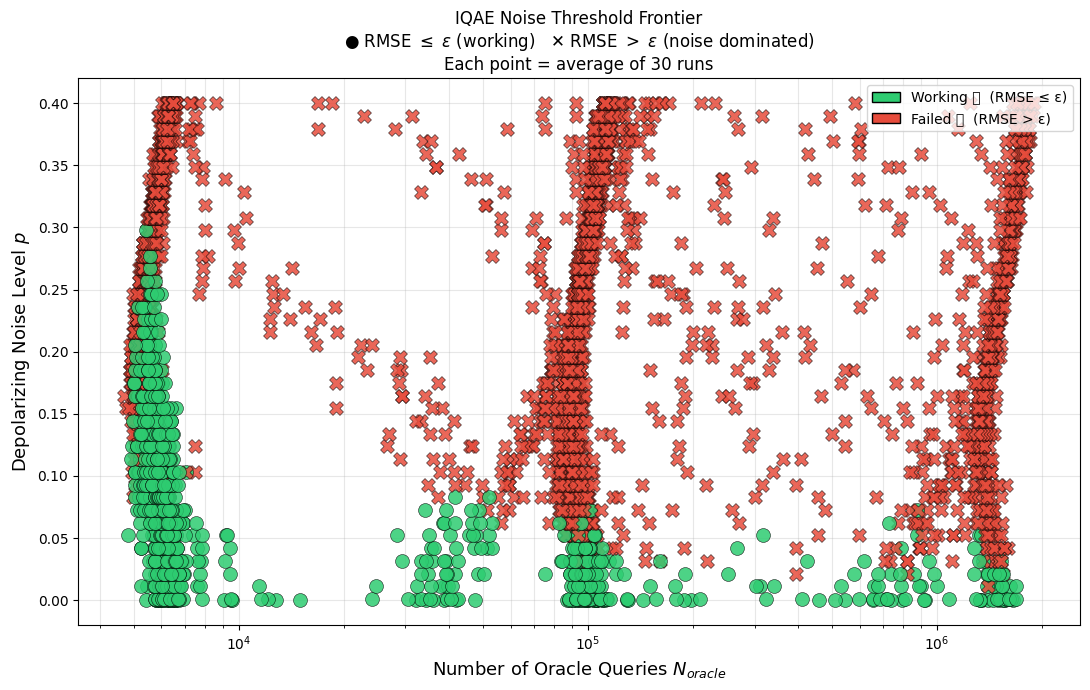

In [56]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 7))

for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'

    ax.scatter(
        entry["queries"],
        entry["noise"],
        color=color,
        marker=marker,
        s=100,
        zorder=5,
        edgecolors='black',
        linewidths=0.4,
        alpha=0.85
    )

ax.set_xscale('log')
#ax.set_yscale('log')
# ✅ Y axis linear — no set_yscale

ax.set_xlabel("Number of Oracle Queries $N_{oracle}$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
ax.set_title(
    "IQAE Noise Threshold Frontier\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs",
    fontsize=12
)
ax.grid(True, which='both', alpha=0.3)

legend_elements = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label='Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label='Failed 💀  (RMSE > ε)'),
]
ax.legend(handles=legend_elements, fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(11, 7))

for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'

    ax.scatter(
        entry["queries"],
        entry["noise"],
        color=color,
        marker=marker,
        s=100,
        zorder=5,
        edgecolors='black',
        linewidths=0.4,
        alpha=0.85
    )

ax.set_xscale('log')
#ax.set_yscale('log')
# ✅ Y axis linear — no set_yscale

ax.set_xlabel("Number of Oracle Queries $N_{oracle}$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
ax.set_title(
    "IQAE Noise Threshold Frontier\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs",
    fontsize=12
)
ax.grid(True, which='both', alpha=0.3)

legend_elements = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label='Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label='Failed 💀  (RMSE > ε)'),
]
ax.legend(handles=legend_elements, fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\3382091984.py:17: RuntimeWarning: divide by zero encountered in log10
  log_q_min = np.log10(queries_all.min())
C:\Users\Percy Cheng\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\_core\function_base.py:163: RuntimeWarning: invalid value encountered in multiply
  y *= step
C:\Users\Percy Cheng\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\_core\function_base.py:173: RuntimeWarning: invalid value encountered in add
  y += start


ValueError: `ydata` must not be empty!

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d

# ── 1. Extract raw arrays from sweep_results ──────────────────────────────────
queries_all   = np.array([e["queries"]   for e in sweep_results])
noise_all     = np.array([e["noise"]     for e in sweep_results])
collapsed_all = np.array([e["collapsed"] for e in sweep_results])

log_q_min = np.log10(queries_all[queries_all > 0].min())
log_q_max = np.log10(queries_all.max())

# ── 2. Bin along log-query axis, extract empirical threshold per bin ───────────
#       Threshold = highest noise level where algorithm is still WORKING
N_BINS     = 60
bin_edges  = np.logspace(log_q_min, log_q_max, N_BINS + 1)

bin_centers = []
thresholds  = []

for i in range(N_BINS):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    in_bin = (queries_all >= lo) & (queries_all < hi)

    if in_bin.sum() == 0:
        continue

    working_noise = noise_all[in_bin & ~collapsed_all]
    thresh        = working_noise.max() if len(working_noise) > 0 else 0.0

    bin_centers.append(np.sqrt(lo * hi))   # geometric centre of bin
    thresholds.append(thresh)

bin_centers = np.array(bin_centers)
thresholds  = np.array(thresholds)

# ── 3. Smooth the raw binned threshold to reduce spike noise ──────────────────
thresholds_smooth = uniform_filter1d(thresholds, size=5)

# ── 4. Fit parametric model: p*(N) = a / (log10(N))^b + c ────────────────────
#       Physically motivated: deeper circuits → more accumulated gate error
#       → tolerable noise falls as a power-law of log(N)
def threshold_model(log_N, a, b, c):
    return a / (log_N ** b) + c

log_centers = np.log10(bin_centers)

try:
    popt, pcov = curve_fit(
        threshold_model,
        log_centers,
        thresholds_smooth,
        p0=[5.0, 1.5, 0.0],
        bounds=([-np.inf, 0.01, -0.5], [np.inf, 10.0, 0.5]),
        maxfev=10_000
    )
    perr   = np.sqrt(np.diag(pcov))
    fit_ok = True
    print(f"✅ Fit converged:")
    print(f"   a = {popt[0]:.4f} ± {perr[0]:.4f}")
    print(f"   b = {popt[1]:.4f} ± {perr[1]:.4f}")
    print(f"   c = {popt[2]:.4f} ± {perr[2]:.4f}")

except RuntimeError as exc:
    fit_ok = False
    print(f"⚠️  curve_fit did not converge: {exc}")
    print("   Falling back to smoothed binned threshold.")

# Dense x-grid for smooth curve rendering
x_dense     = np.logspace(log_q_min, log_q_max, 600)
log_x_dense = np.log10(x_dense)

if fit_ok:
    y_curve = np.clip(threshold_model(log_x_dense, *popt), 0, noise_all.max())
else:
    # Fallback: linear interpolation through smoothed bins
    y_curve = np.clip(np.interp(x_dense, bin_centers, thresholds_smooth), 0, noise_all.max())

# ── 5. Reproduce exact scatter plot ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 7))

for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'

    ax.scatter(
        entry["queries"],
        entry["noise"],
        color=color,
        marker=marker,
        s=100,
        zorder=5,
        edgecolors='black',
        linewidths=0.4,
        alpha=0.85
    )

# ── 6. Overlay threshold curve ────────────────────────────────────────────────
ax.plot(
    x_dense, y_curve,
    color='gold',
    linewidth=2.8,
    linestyle='--',
    zorder=10,
    label='Fitted threshold $p^*(N)$'
)

# Shaded safe zone below the curve
ax.fill_between(
    x_dense, 0, y_curve,
    color='gold',
    alpha=0.12,
    zorder=4,
)

# Raw smoothed bin markers — shows what the fit is tracking
ax.scatter(
    bin_centers,
    thresholds_smooth,
    color='white',
    edgecolors='gold',
    linewidths=1.8,
    s=60,
    zorder=11,
)

# ── 7. Axes, labels, legend ───────────────────────────────────────────────────
ax.set_xscale('log')
ax.set_xlim(10 ** log_q_min, 10 ** log_q_max)
ax.set_ylim(-0.01, noise_all.max() + 0.02)

ax.set_xlabel("Number of Oracle Queries $N_{oracle}$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)

if fit_ok:
    curve_label = (
        f"$p^*(N) = "
        f"\\dfrac{{{popt[0]:.3f}}}{{(\\log_{{10}}N)^{{{popt[1]:.3f}}}}} "
        f"{'+' if popt[2] >= 0 else '-'} {abs(popt[2]):.3f}$"
    )
else:
    curve_label = "Smoothed empirical threshold (fit failed)"

ax.set_title(
    "IQAE Noise Threshold Frontier\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs",
    fontsize=12
)

legend_elements = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label='Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label='Failed 💀  (RMSE > ε)'),
    plt.Line2D([0], [0], color='gold', linewidth=2.5, linestyle='--',
               label=f'Threshold curve:\n  {curve_label}'),
    mpatches.Patch(facecolor='gold', alpha=0.25, edgecolor='none',
                   label='Predicted safe region'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='white',
               markeredgecolor='gold', markeredgewidth=1.8, markersize=8,
               label='Binned threshold (smoothed)'),
]
ax.legend(handles=legend_elements, fontsize=9, loc='upper right', framealpha=0.88)
ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

# ── 8. Summary ────────────────────────────────────────────────────────────────
if fit_ok:
    print("\n📐 Fitted threshold model:")
    print(f"   p*(N) = {popt[0]:.4f} / (log₁₀N)^{popt[1]:.4f} + {popt[2]:.4f}")
    print("\n   Physical interpretation:")
    print("   → More oracle queries = deeper circuits = more accumulated depolarizing error")
    print("   → The tolerable noise p* decreases as a power-law of log₁₀(N)")
    print(f"   → At N=10⁴ queries: p* ≈ {threshold_model(4, *popt):.4f}")
    print(f"   → At N=10⁵ queries: p* ≈ {threshold_model(5, *popt):.4f}")
    print(f"   → At N=10⁶ queries: p* ≈ {threshold_model(6, *popt):.4f}")

✅ Fit converged:
   a = 82691.4330 ± 256223.7152
   b = 10.0000 ± 2.3338
   c = 0.0152 ± 0.0076


C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\554074282.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\554074282.py:170: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


KeyboardInterrupt: 

Model                                    Params       RMSE         R²     Status
Log-Simple  [a / log(N)]                      1   0.049428   0.129087       ✅ OK
Log-Power   [a / (log(N))^b]                  2   0.032094   0.632822       ✅ OK
Power-Law   [a / N^b]                         2   0.032241   0.629448       ✅ OK
Exp-Decay   [a·exp(-b·log(N))]                2   0.032241   0.629448       ✅ OK

🏆 Best model : Log-Power   [a / (log(N))^b]
   R²        : 0.632822   ← selection criterion
   RMSE      : 0.032094   ← physical units (noise level)
   a         : 51263092585.023987 ± 183373974295.670258
   b         : 19.840402 ± 2.696209
   Asymptote : p*(N) → 0  ✅


Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\2991419106.py:355: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\2991419106.py:355: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.


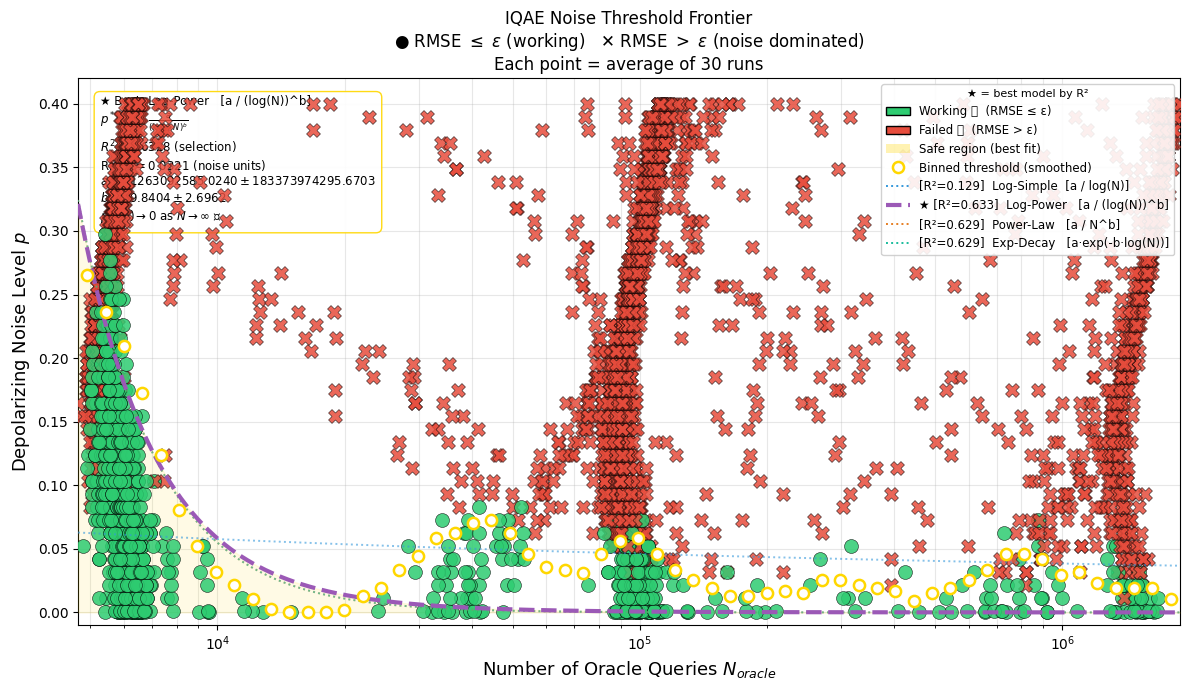


📊 Full model comparison:
Model                                            R²       RMSE   Params Winner
--------------------------------------------------------------------------------
Log-Power   [a / (log(N))^b]               0.632822   0.032094        2      🏆
Exp-Decay   [a·exp(-b·log(N))]             0.629448   0.032241        2        
Power-Law   [a / N^b]                      0.629448   0.032241        2        
Log-Simple  [a / log(N)]                   0.129087   0.049428        1        

📐 Threshold predictions — best model (Log-Power   [a / (log(N))^b]):
   N                    p*(N)   Note
   --------------------------------------------------
   N = 10^3            1.0000   ← extrapolated
   N = 10^4            0.0582   ← within sweep
   N = 10^5            0.0007   ← within sweep
   N = 10^6            0.0000   ← within sweep
   N = 10^7            0.0000   ← extrapolated

📌 Metric rationale:
   R²   → model selection  : scale-free, measures explained variance
   RMSE →

In [67]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d

# ══════════════════════════════════════════════════════════════════════════════
# 1. EXTRACT RAW ARRAYS
# ══════════════════════════════════════════════════════════════════════════════
queries_all   = np.array([e["queries"]   for e in sweep_results])
noise_all     = np.array([e["noise"]     for e in sweep_results])
collapsed_all = np.array([e["collapsed"] for e in sweep_results])

log_q_min = np.log10(queries_all[queries_all > 0].min())
log_q_max = np.log10(queries_all.max())

# ══════════════════════════════════════════════════════════════════════════════
# 2. BIN ON LOG-QUERY AXIS & EXTRACT EMPIRICAL THRESHOLD PER BIN
#    Threshold = highest noise where algorithm is still working (green ●)
#    Geometric mean used as bin centre — correct average on log scale
# ══════════════════════════════════════════════════════════════════════════════
N_BINS    = 60
bin_edges = np.logspace(log_q_min, log_q_max, N_BINS + 1)

bin_centers = []
thresholds  = []

for i in range(N_BINS):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    in_bin = (queries_all >= lo) & (queries_all < hi)

    if in_bin.sum() == 0:
        continue

    working_noise = noise_all[in_bin & ~collapsed_all]
    thresh        = working_noise.max() if len(working_noise) > 0 else 0.0

    bin_centers.append(np.sqrt(lo * hi))
    thresholds.append(thresh)

bin_centers = np.array(bin_centers)
thresholds  = np.array(thresholds)

# ══════════════════════════════════════════════════════════════════════════════
# 3. SMOOTH — removes single-bin spikes from IQAE's discrete round structure
# ══════════════════════════════════════════════════════════════════════════════
thresholds_smooth = uniform_filter1d(thresholds, size=5)

# ══════════════════════════════════════════════════════════════════════════════
# 4. METRICS
#
#    R²   — scale-free, used for MODEL SELECTION
#            R² = 1 - SS_res / SS_tot
#            SS_res = Σ(y_true - y_pred)²
#            SS_tot = Σ(y_true - ȳ)²
#
#    RMSE — in noise units [0, 0.4], used for PHYSICAL INTERPRETATION
#            RMSE = sqrt( mean( (y_true - y_pred)² ) )
#
#    Selection: highest R² → most variance explained, scale-free
#    Tiebreaker: lowest RMSE
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (ss_res / ss_tot)

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# 5. CANDIDATE MODELS — all asymptote to 0 as N → ∞
#
#    Physical justification:
#      Fidelity after d noisy gates: F(d) = (1-p)^d → 0 for any fixed p > 0
#      More queries ↔ deeper circuits ↔ more gate layers
#      Therefore NO noise floor exists — any p > 0 eventually destroys IQAE
#      → p*(N) must strictly → 0
#
#    MODEL 1: a / log10(N)
#      Simplest log decay. Single free parameter.
#      Decays very slowly — may overestimate threshold at large N.
#
#    MODEL 2: a / (log10(N))^b
#      Power-law in log. Two free parameters.
#      b controls how fast the threshold decays with depth.
#      b > 1 → faster decay, b < 1 → slower decay.
#
#    MODEL 3: a / N^b
#      Direct power law in N. Two free parameters.
#      Directly motivated by fidelity decay (1-p)^N ~ e^{-pN}.
#      b ≈ 1 expected from theory.
#
#    MODEL 4: a * exp(-b * log10(N))
#      Exponential in log10(N). Mathematically ≡ a * N^{-b*log(10)}.
#      Numerically more stable than Model 3 for large N.
# ══════════════════════════════════════════════════════════════════════════════
def model_log_simple(log_N, a):
    """
    p* = a / log10(N)
    Simplest log decay — 1 parameter, decays slowly.
    Asymptote: p* → 0 as N → ∞  ✅
    """
    return a / log_N

def model_log_power(log_N, a, b):
    """
    p* = a / (log10(N))^b
    Power-law in log — 2 parameters, b controls decay rate.
    Asymptote: p* → 0 as N → ∞  ✅
    """
    return a / (log_N ** b)

def model_power_law(log_N, a, b):
    """
    p* = a / N^b
    Direct power law in N — motivated by fidelity decay (1-p)^N.
    Asymptote: p* → 0 as N → ∞  ✅
    """
    return a / ((10 ** log_N) ** b)

def model_exp_decay(log_N, a, b):
    """
    p* = a * exp(-b * log10(N))  ≡  a * N^{-b*ln(10)}
    Exponential in log10(N) — numerically stable reparametrisation.
    Asymptote: p* → 0 as N → ∞  ✅
    """
    return a * np.exp(-b * log_N)

candidates = {
    "Log-Simple  [a / log(N)]" : {
        "func"    : model_log_simple,
        "p0"      : [1.0],
        "bounds"  : ([0.0], [np.inf]),
        "n_params": 1,
        "tex"     : r"$p^*(N)=\frac{a}{\log_{10}N}$",
        "color"   : "#3498db",   # blue
    },
    "Log-Power   [a / (log(N))^b]" : {
        "func"    : model_log_power,
        "p0"      : [5.0, 1.5],
        "bounds"  : ([0.0, 0.001], [np.inf, np.inf]),
        "n_params": 2,
        "tex"     : r"$p^*(N)=\frac{a}{(\log_{10}N)^b}$",
        "color"   : "#9b59b6",   # purple
    },
    "Power-Law   [a / N^b]" : {
        "func"    : model_power_law,
        "p0"      : [1.0, 0.3],
        "bounds"  : ([0.0, 0.001], [np.inf, np.inf]),
        "n_params": 2,
        "tex"     : r"$p^*(N)=\frac{a}{N^b}$",
        "color"   : "#e67e22",   # orange
    },
    "Exp-Decay   [a·exp(-b·log(N))]" : {
        "func"    : model_exp_decay,
        "p0"      : [1.0, 1.0],
        "bounds"  : ([0.0, 0.001], [np.inf, np.inf]),
        "n_params": 2,
        "tex"     : r"$p^*(N)=a\cdot e^{-b\log_{10}N}$",
        "color"   : "#1abc9c",   # teal
    },
}

log_centers = np.log10(bin_centers)
fit_results = {}

# ══════════════════════════════════════════════════════════════════════════════
# 6. FIT ALL CANDIDATES
# ══════════════════════════════════════════════════════════════════════════════
print("=" * 85)
print(f"{'Model':<40} {'Params':>6} {'RMSE':>10} {'R²':>10} {'Status':>10}")
print("=" * 85)

for label, cfg in candidates.items():
    try:
        popt, pcov = curve_fit(
            cfg["func"],
            log_centers,
            thresholds_smooth,
            p0=cfg["p0"],
            bounds=cfg["bounds"],
            maxfev=20_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = cfg["func"](log_centers, *popt)
        r2     = r_squared(thresholds_smooth, y_pred)
        rm     = rmse(thresholds_smooth, y_pred)

        fit_results[label] = {
            "popt"    : popt,
            "perr"    : perr,
            "r2"      : r2,
            "rmse"    : rm,
            "func"    : cfg["func"],
            "n_params": cfg["n_params"],
            "tex"     : cfg["tex"],
            "color"   : cfg["color"],
        }

        print(f"{label:<40} {cfg['n_params']:>6} {rm:>10.6f} {r2:>10.6f} {'✅ OK':>10}")

    except RuntimeError as exc:
        print(f"{label:<40} {'—':>6} {'—':>10} {'—':>10} {'❌ Failed':>10}")
        print(f"   ↳ {exc}")

print("=" * 85)

# ══════════════════════════════════════════════════════════════════════════════
# 7. SELECT BEST MODEL
#    Primary   : highest R²   (scale-free, measures explained variance)
#    Secondary : lowest RMSE  (tiebreaker, physical noise units)
# ══════════════════════════════════════════════════════════════════════════════
best_label = max(fit_results, key=lambda k: (fit_results[k]["r2"],
                                             -fit_results[k]["rmse"]))
best = fit_results[best_label]

print(f"\n🏆 Best model : {best_label}")
print(f"   R²        : {best['r2']:.6f}   ← selection criterion")
print(f"   RMSE      : {best['rmse']:.6f}   ← physical units (noise level)")
for i, (pv, pe) in enumerate(zip(best["popt"], best["perr"])):
    param_name = ["a", "b", "c"][i]
    print(f"   {param_name}         : {pv:.6f} ± {pe:.6f}")
print(f"   Asymptote : p*(N) → 0  ✅")

# ══════════════════════════════════════════════════════════════════════════════
# 8. DENSE CURVES FOR ALL MODELS
# ══════════════════════════════════════════════════════════════════════════════
x_dense     = np.logspace(log_q_min, log_q_max, 600)
log_x_dense = np.log10(x_dense)

# ══════════════════════════════════════════════════════════════════════════════
# 9. PLOT — scatter + all curves + best highlighted
# ══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(12, 7))

# — Scatter points
for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'
    ax.scatter(
        entry["queries"], entry["noise"],
        color=color, marker=marker, s=100,
        zorder=5, edgecolors='black', linewidths=0.4, alpha=0.85
    )

# — All candidate curves (thin, semi-transparent)
for label, res in fit_results.items():
    y_dense = np.clip(res["func"](log_x_dense, *res["popt"]), 0, noise_all.max())
    is_best = (label == best_label)
    ax.plot(
        x_dense, y_dense,
        color    = res["color"],
        linewidth= 3.0 if is_best else 1.4,
        linestyle= '--' if is_best else ':',
        alpha    = 1.0  if is_best else 0.6,
        zorder   = 12   if is_best else 9,
        label    = f"{'★ ' if is_best else ''}[R²={res['r2']:.3f} | RMSE={res['rmse']:.4f}]  {label}"
    )

# — Safe zone shading under best curve only
y_best_dense = np.clip(best["func"](log_x_dense, *best["popt"]), 0, noise_all.max())
ax.fill_between(
    x_dense, 0, y_best_dense,
    color='gold', alpha=0.10, zorder=4, label='Safe region (best fit)'
)

# — Smoothed bin markers (what all curves were fit to)
ax.scatter(
    bin_centers, thresholds_smooth,
    color='white', edgecolors='gold',
    linewidths=1.8, s=65, zorder=13,
    label='Binned threshold (smoothed)'
)

# ══════════════════════════════════════════════════════════════════════════════
# 10. STATS ANNOTATION BOX — best model only
# ══════════════════════════════════════════════════════════════════════════════
p = best["popt"]
e = best["perr"]
param_lines = "\n".join([
    f"${'abc'[i]} = {p[i]:.4f} \\pm {e[i]:.4f}$"
    for i in range(len(p))
])

stats_text = (
    f"★ Best: {best_label.strip()}\n"
    f"{best['tex']}\n"
    f"$R^2 = {best['r2']:.4f}$ (selection)\n"
    f"$\\mathrm{{RMSE}} = {best['rmse']:.4f}$ (noise units)\n"
    f"{param_lines}\n"
    f"$p^*(N) \\to 0$ as $N \\to \\infty$ ✅"
)
ax.text(
    0.02, 0.97, stats_text,
    transform=ax.transAxes,
    fontsize=8.5,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
              edgecolor='gold', alpha=0.92)
)

# ══════════════════════════════════════════════════════════════════════════════
# 11. AXES, LABELS, LEGEND
# ══════════════════════════════════════════════════════════════════════════════
ax.set_xscale('log')
ax.set_xlim(10 ** log_q_min, 10 ** log_q_max)
ax.set_ylim(-0.01, noise_all.max() + 0.02)
ax.set_xlabel("Number of Oracle Queries $N_{oracle}$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
ax.set_title(
    "IQAE Noise Threshold Frontier\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs",
    fontsize=12
)

# — Base legend entries
base_legend = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label='Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label='Failed 💀  (RMSE > ε)'),
    mpatches.Patch(facecolor='gold', alpha=0.3, edgecolor='none',
                   label='Safe region (best fit)'),
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='white', markeredgecolor='gold',
               markeredgewidth=1.8, markersize=8,
               label='Binned threshold (smoothed)'),
]

# — One legend entry per fitted model (colour coded)
model_legend = [
    plt.Line2D(
        [0], [0],
        color    = res["color"],
        linewidth= 3.0 if lbl == best_label else 1.4,
        linestyle= '--' if lbl == best_label else ':',
        label    = f"{'★ ' if lbl == best_label else ''}[R²={res['r2']:.3f}]  {lbl}"
    )
    for lbl, res in fit_results.items()
]

ax.legend(
    handles   = base_legend + model_legend,
    fontsize  = 8.5,
    loc       = 'upper right',
    framealpha= 0.90,
    title     = "★ = best model by R²",
    title_fontsize = 8,
)
ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# 12. FULL COMPARISON TABLE + PREDICTIONS
# ══════════════════════════════════════════════════════════════════════════════
print("\n📊 Full model comparison:")
print(f"{'Model':<40} {'R²':>10} {'RMSE':>10} {'Params':>8} {'Winner'}")
print("-" * 80)
for lbl, res in sorted(fit_results.items(),
                        key=lambda x: x[1]["r2"], reverse=True):
    star = "🏆" if lbl == best_label else "  "
    print(f"{lbl:<40} {res['r2']:>10.6f} {res['rmse']:>10.6f} "
          f"{res['n_params']:>8}      {star}")

print(f"\n📐 Threshold predictions — best model ({best_label.strip()}):")
print(f"   {'N':<15} {'p*(N)':>10}   {'Note'}")
print(f"   {'-' * 50}")
for exp in [3, 4, 5, 6, 7]:
    val  = float(np.clip(best["func"](exp, *best["popt"]), 0, 1))
    note = "← within sweep" if log_q_min <= exp <= log_q_max else "← extrapolated"
    print(f"   N = 10^{exp:<8} {val:>10.4f}   {note}")

print(f"\n📌 Metric rationale:")
print(f"   R²   → model selection  : scale-free, measures explained variance")
print(f"   RMSE → physical meaning : 'curve is off by X in noise level on average'")
print(f"   All models enforce p*(N) → 0  (no spurious noise floor)")

Model                                      Params       RMSE         R²     Status
Log-Simple  [a / |log(ε)|]                      1   0.049350   0.763326       ✅ OK
Log-Power   [a / |log(ε)|^b]                    2   0.015035   0.978032       ✅ OK
Power-Eps   [a · ε^b]                           2   0.010469   0.989349       ✅ OK
Exp-Decay   [a · exp(-b·|log(ε)|)]              2   0.010469   0.989349       ✅ OK

🏆 Best model : Exp-Decay   [a · exp(-b·|log(ε)|)]
   R²        : 0.989349   ← selection criterion (scale-free)
   RMSE      : 0.010469   ← physical units (noise level)
   a         : 1.199259 ± 0.036228
   b         : 1.095439 ± 0.019894
   Asymptote : p*(ε) → 0 as ε → 0  ✅


Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\256517163.py:380: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Percy Cheng\AppData\Local\Temp\ipykernel_27412\256517163.py:380: UserWarning: Glyph 128128 (\N{SKULL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
Font 'default' does not have a glyph for '\u2705' [U+2705], substituting with a dummy symbol.


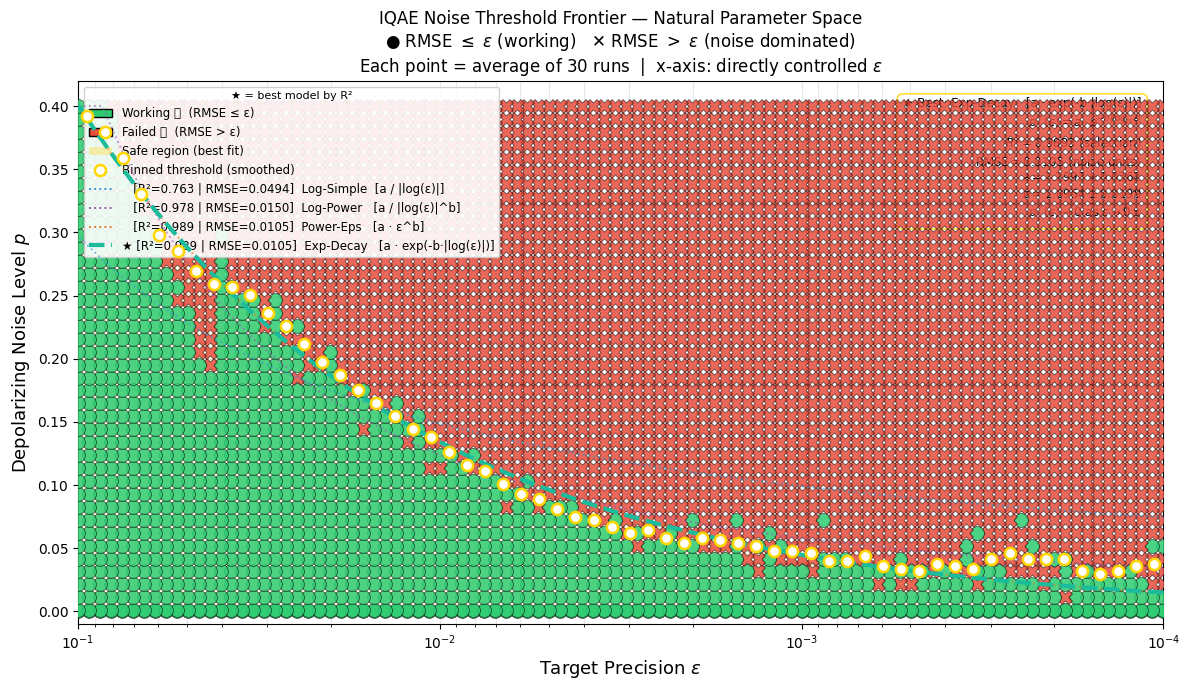


📊 Full model comparison (ranked by R²):
Model                                              R²       RMSE   Params  Winner
--------------------------------------------------------------------------------
Exp-Decay   [a · exp(-b·|log(ε)|)]           0.989349   0.010469        2  🏆
Power-Eps   [a · ε^b]                        0.989349   0.010469        2    
Log-Power   [a / |log(ε)|^b]                 0.978032   0.015035        2    
Log-Simple  [a / |log(ε)|]                   0.763326   0.049350        1    

📐 Threshold predictions — best model (Exp-Decay   [a · exp(-b·|log(ε)|)]):
   ε                 p*(ε)   Note
   --------------------------------------------------
   ε = 0.1            0.4010   ← within sweep
   ε = 0.05           0.2884   ← within sweep
   ε = 0.01           0.1341   ← within sweep
   ε = 0.005          0.0964   ← within sweep
   ε = 0.001          0.0448   ← within sweep
   ε = 0.0005         0.0322   ← within sweep
   ε = 0.0001         0.0150   ← within sweep

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.optimize import curve_fit
from scipy.ndimage import uniform_filter1d

# ══════════════════════════════════════════════════════════════════════════════
# 1. EXTRACT RAW ARRAYS
#    Working in ε-space — the natural parameter space of the sweep
#    ε is directly controlled, noise is the y-axis
# ══════════════════════════════════════════════════════════════════════════════
epsilon_all   = np.array([e["epsilon"]   for e in sweep_results])
noise_all     = np.array([e["noise"]     for e in sweep_results])
collapsed_all = np.array([e["collapsed"] for e in sweep_results])

log_eps_min = np.log10(epsilon_all.min())
log_eps_max = np.log10(epsilon_all.max())

# ══════════════════════════════════════════════════════════════════════════════
# 2. BIN ON LOG-ε AXIS & EXTRACT EMPIRICAL THRESHOLD PER BIN
#
#    Threshold = highest noise where algorithm is still working (green ●)
#    in each ε bin.
#
#    Note on direction:
#      Small ε → deep circuits → noise-sensitive → low threshold
#      Large ε → shallow circuits → noise-tolerant → high threshold
#    So p*(ε) is INCREASING in ε (opposite direction to p*(N))
#
#    Geometric mean used as bin centre — correct average on log scale
# ══════════════════════════════════════════════════════════════════════════════
N_BINS    = 60
bin_edges = np.logspace(log_eps_min, log_eps_max, N_BINS + 1)

bin_centers = []
thresholds  = []

for i in range(N_BINS):
    lo, hi = bin_edges[i], bin_edges[i + 1]
    in_bin = (epsilon_all >= lo) & (epsilon_all < hi)

    if in_bin.sum() == 0:
        continue

    working_noise = noise_all[in_bin & ~collapsed_all]
    thresh        = working_noise.max() if len(working_noise) > 0 else 0.0

    bin_centers.append(np.sqrt(lo * hi))   # geometric mean
    thresholds.append(thresh)

bin_centers = np.array(bin_centers)
thresholds  = np.array(thresholds)

# ══════════════════════════════════════════════════════════════════════════════
# 3. SMOOTH — removes single-bin spikes
# ══════════════════════════════════════════════════════════════════════════════
thresholds_smooth = uniform_filter1d(thresholds, size=5)

# ══════════════════════════════════════════════════════════════════════════════
# 4. METRICS
#
#    R²   — scale-free, PRIMARY selection criterion
#            R² = 1 - SS_res / SS_tot
#            Measures fraction of variance in threshold explained by model
#
#    RMSE — in noise units [0, 0.4], PHYSICAL INTERPRETATION
#            RMSE = sqrt( mean( (y_true - y_pred)² ) )
#            "curve is off by X in noise level on average"
#
#    Both computed for every candidate.
#    Winner = highest R², RMSE as tiebreaker.
# ══════════════════════════════════════════════════════════════════════════════
def r_squared(y_true, y_pred):
    """R² = 1 - SS_res / SS_tot"""
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - (ss_res / ss_tot)

def rmse(y_true, y_pred):
    """RMSE in noise units"""
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

# ══════════════════════════════════════════════════════════════════════════════
# 5. CANDIDATE MODELS — in ε-space
#
#    Physical justification (ε-space):
#      ε ↓  →  N_oracle ~ 1/ε ↑  →  deeper circuits  →  more noise accumulation
#      ε ↑  →  N_oracle ~ 1/ε ↓  →  shallower circuits →  more noise tolerated
#
#    Therefore p*(ε) is INCREASING in ε — all models must satisfy:
#      p*(ε) → 0  as  ε → 0   (deep circuits, any noise destroys them)
#      p*(ε) → ∞  as  ε → 1   (trivial circuit, noise irrelevant — clipped to p_max)
#
#    Working in log10(ε) space for numerical stability.
#    Note: log10(ε) is NEGATIVE (ε ∈ [0.0001, 0.1])
#    So we use |log10(ε)| = -log10(ε) = log10(1/ε) in denominators
#
#    MODEL 1: a / |log10(ε)|
#      Simplest — 1 parameter. Slow decay as ε → 0.
#
#    MODEL 2: a / |log10(ε)|^b
#      Power-law in log. b controls decay rate.
#      b > 1 → faster decay toward 0 as ε shrinks.
#
#    MODEL 3: a * ε^b
#      Direct power law in ε. Motivated by N ~ 1/ε → p* ~ ε^b.
#      b ≈ 1 expected from fidelity decay theory.
#      Most physically motivated model in ε-space.
#
#    MODEL 4: a * exp(-b * |log10(ε)|)  ≡  a * ε^{b*ln(10)}
#      Exponential in |log10(ε)|. Numerically stable reparametrisation.
#      Mathematically equivalent to Model 3.
# ══════════════════════════════════════════════════════════════════════════════
def model_log_simple(log_eps, a):
    """
    p* = a / |log10(ε)|
    1 parameter. Slow decay as ε → 0.
    Asymptote: p* → 0 as ε → 0  ✅
    """
    return a / np.abs(log_eps)

def model_log_power(log_eps, a, b):
    """
    p* = a / |log10(ε)|^b
    2 parameters. b controls decay rate.
    Asymptote: p* → 0 as ε → 0  ✅
    """
    return a / (np.abs(log_eps) ** b)

def model_power_eps(log_eps, a, b):
    """
    p* = a * ε^b  =  a * 10^(b * log10(ε))
    2 parameters. Directly motivated by N ~ 1/ε.
    Asymptote: p* → 0 as ε → 0  ✅
    """
    return a * (10 ** (b * log_eps))

def model_exp_decay(log_eps, a, b):
    """
    p* = a * exp(-b * |log10(ε)|)  ≡  a * ε^{b*ln(10)}
    2 parameters. Numerically stable reparametrisation of power law.
    Asymptote: p* → 0 as ε → 0  ✅
    """
    return a * np.exp(-b * np.abs(log_eps))

candidates = {
    "Log-Simple  [a / |log(ε)|]" : {
        "func"    : model_log_simple,
        "p0"      : [0.5],
        "bounds"  : ([0.0], [np.inf]),
        "n_params": 1,
        "tex"     : r"$p^*(\epsilon)=\frac{a}{|\log_{10}\epsilon|}$",
        "color"   : "#3498db",    # blue
    },
    "Log-Power   [a / |log(ε)|^b]" : {
        "func"    : model_log_power,
        "p0"      : [0.5, 1.5],
        "bounds"  : ([0.0, 0.001], [np.inf, np.inf]),
        "n_params": 2,
        "tex"     : r"$p^*(\epsilon)=\frac{a}{|\log_{10}\epsilon|^b}$",
        "color"   : "#9b59b6",    # purple
    },
    "Power-Eps   [a · ε^b]" : {
        "func"    : model_power_eps,
        "p0"      : [1.0, 0.5],
        "bounds"  : ([0.0, 0.001], [np.inf, np.inf]),
        "n_params": 2,
        "tex"     : r"$p^*(\epsilon)=a\cdot\epsilon^b$",
        "color"   : "#e67e22",    # orange
    },
    "Exp-Decay   [a · exp(-b·|log(ε)|)]" : {
        "func"    : model_exp_decay,
        "p0"      : [1.0, 1.0],
        "bounds"  : ([0.0, 0.001], [np.inf, np.inf]),
        "n_params": 2,
        "tex"     : r"$p^*(\epsilon)=a\cdot e^{-b|\log_{10}\epsilon|}$",
        "color"   : "#1abc9c",    # teal
    },
}

log_centers = np.log10(bin_centers)   # negative values since ε < 1
fit_results = {}

# ══════════════════════════════════════════════════════════════════════════════
# 6. FIT ALL CANDIDATES
# ══════════════════════════════════════════════════════════════════════════════
print("=" * 85)
print(f"{'Model':<42} {'Params':>6} {'RMSE':>10} {'R²':>10} {'Status':>10}")
print("=" * 85)

for label, cfg in candidates.items():
    try:
        popt, pcov = curve_fit(
            cfg["func"],
            log_centers,
            thresholds_smooth,
            p0=cfg["p0"],
            bounds=cfg["bounds"],
            maxfev=20_000
        )
        perr   = np.sqrt(np.diag(pcov))
        y_pred = cfg["func"](log_centers, *popt)
        r2     = r_squared(thresholds_smooth, y_pred)
        rm     = rmse(thresholds_smooth, y_pred)

        fit_results[label] = {
            "popt"    : popt,
            "perr"    : perr,
            "r2"      : r2,
            "rmse"    : rm,
            "func"    : cfg["func"],
            "n_params": cfg["n_params"],
            "tex"     : cfg["tex"],
            "color"   : cfg["color"],
        }

        print(f"{label:<42} {cfg['n_params']:>6} {rm:>10.6f} {r2:>10.6f} {'✅ OK':>10}")

    except RuntimeError as exc:
        print(f"{label:<42} {'—':>6} {'—':>10} {'—':>10} {'❌ Failed':>10}")
        print(f"   ↳ {exc}")

print("=" * 85)

# ══════════════════════════════════════════════════════════════════════════════
# 7. SELECT BEST MODEL
#    Primary   : highest R²   (scale-free, measures explained variance)
#    Secondary : lowest RMSE  (tiebreaker, physical noise units)
# ══════════════════════════════════════════════════════════════════════════════
best_label = max(fit_results, key=lambda k: (fit_results[k]["r2"],
                                             -fit_results[k]["rmse"]))
best = fit_results[best_label]

print(f"\n🏆 Best model : {best_label}")
print(f"   R²        : {best['r2']:.6f}   ← selection criterion (scale-free)")
print(f"   RMSE      : {best['rmse']:.6f}   ← physical units (noise level)")
for i, (pv, pe) in enumerate(zip(best["popt"], best["perr"])):
    print(f"   {'abc'[i]}         : {pv:.6f} ± {pe:.6f}")
print(f"   Asymptote : p*(ε) → 0 as ε → 0  ✅")

# ══════════════════════════════════════════════════════════════════════════════
# 8. DENSE CURVES FOR SMOOTH RENDERING
# ══════════════════════════════════════════════════════════════════════════════
x_dense     = np.logspace(log_eps_min, log_eps_max, 600)
log_x_dense = np.log10(x_dense)

# ══════════════════════════════════════════════════════════════════════════════
# 9. PLOT — scatter + all curves + best highlighted
# ══════════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(12, 7))

# — Scatter points
for entry in sweep_results:
    color  = '#e74c3c' if entry["collapsed"] else '#2ecc71'
    marker = 'X'       if entry["collapsed"] else 'o'
    ax.scatter(
        entry["epsilon"],
        entry["noise"],
        color=color,
        marker=marker,
        s=100,
        zorder=5,
        edgecolors='black',
        linewidths=0.4,
        alpha=0.85
    )

# — All candidate curves
for label, res in fit_results.items():
    y_dense = np.clip(res["func"](log_x_dense, *res["popt"]), 0, noise_all.max())
    is_best = (label == best_label)
    ax.plot(
        x_dense, y_dense,
        color    = res["color"],
        linewidth= 3.0  if is_best else 1.4,
        linestyle= '--' if is_best else ':',
        alpha    = 1.0  if is_best else 0.6,
        zorder   = 12   if is_best else 9,
    )

# — Safe zone shading under best curve only
y_best_dense = np.clip(best["func"](log_x_dense, *best["popt"]), 0, noise_all.max())
ax.fill_between(
    x_dense, 0, y_best_dense,
    color='gold', alpha=0.10, zorder=4
)

# — Smoothed bin markers
ax.scatter(
    bin_centers, thresholds_smooth,
    color='white', edgecolors='gold',
    linewidths=1.8, s=65, zorder=13,
)

# ══════════════════════════════════════════════════════════════════════════════
# 10. STATS ANNOTATION BOX
# ══════════════════════════════════════════════════════════════════════════════
p = best["popt"]
e = best["perr"]
param_lines = "\n".join([
    f"${'abc'[i]} = {p[i]:.4f} \\pm {e[i]:.4f}$"
    for i in range(len(p))
])

stats_text = (
    f"★ Best: {best_label.strip()}\n"
    f"{best['tex']}\n"
    f"$R^2 = {best['r2']:.4f}$ (selection)\n"
    f"$\\mathrm{{RMSE}} = {best['rmse']:.4f}$ (noise units)\n"
    f"{param_lines}\n"
    f"$p^*(\\epsilon) \\to 0$ as $\\epsilon \\to 0$ ✅"
)
ax.text(
    0.98, 0.97, stats_text,
    transform=ax.transAxes,
    fontsize=8.5,
    verticalalignment='top',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
              edgecolor='gold', alpha=0.92)
)

# ══════════════════════════════════════════════════════════════════════════════
# 11. AXES, LABELS, LEGEND
# ══════════════════════════════════════════════════════════════════════════════
ax.set_xscale('log')
ax.invert_xaxis()   # small ε (hard) on right, large ε (easy) on left
ax.set_xlim(10 ** log_eps_max, 10 ** log_eps_min)
ax.set_ylim(-0.01, noise_all.max() + 0.02)
ax.set_xlabel(r"Target Precision $\epsilon$", fontsize=13)
ax.set_ylabel("Depolarizing Noise Level $p$", fontsize=13)
ax.set_title(
    "IQAE Noise Threshold Frontier — Natural Parameter Space\n"
    f"● RMSE $\\leq$ $\\epsilon$ (working)   "
    f"✕ RMSE $>$ $\\epsilon$ (noise dominated)\n"
    f"Each point = average of {N_REPEATS} runs  |  "
    f"x-axis: directly controlled $\\epsilon$",
    fontsize=12
)

# — Base legend entries
base_legend = [
    mpatches.Patch(facecolor='#2ecc71', edgecolor='black',
                   label='Working ✅  (RMSE ≤ ε)'),
    mpatches.Patch(facecolor='#e74c3c', edgecolor='black',
                   label='Failed 💀  (RMSE > ε)'),
    mpatches.Patch(facecolor='gold', alpha=0.3, edgecolor='none',
                   label='Safe region (best fit)'),
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor='white', markeredgecolor='gold',
               markeredgewidth=1.8, markersize=8,
               label='Binned threshold (smoothed)'),
]

# — One entry per model, colour coded
model_legend = [
    plt.Line2D(
        [0], [0],
        color    = res["color"],
        linewidth= 3.0  if lbl == best_label else 1.4,
        linestyle= '--' if lbl == best_label else ':',
        label    = (
            f"{'★ ' if lbl == best_label else '   '}"
            f"[R²={res['r2']:.3f} | RMSE={res['rmse']:.4f}]  {lbl}"
        )
    )
    for lbl, res in fit_results.items()
]

ax.legend(
    handles        = base_legend + model_legend,
    fontsize       = 8.5,
    loc            = 'upper left',
    framealpha     = 0.90,
    title          = "★ = best model by R²",
    title_fontsize = 8,
)
ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════════════════
# 12. FULL COMPARISON TABLE + PREDICTIONS
# ══════════════════════════════════════════════════════════════════════════════
print("\n📊 Full model comparison (ranked by R²):")
print(f"{'Model':<42} {'R²':>10} {'RMSE':>10} {'Params':>8}  {'Winner'}")
print("-" * 80)
for lbl, res in sorted(fit_results.items(),
                        key=lambda x: x[1]["r2"], reverse=True):
    star = "🏆" if lbl == best_label else "  "
    print(f"{lbl:<42} {res['r2']:>10.6f} {res['rmse']:>10.6f} "
          f"{res['n_params']:>8}  {star}")

print(f"\n📐 Threshold predictions — best model ({best_label.strip()}):")
print(f"   {'ε':<12} {'p*(ε)':>10}   {'Note'}")
print(f"   {'-' * 50}")
for eps_val in [0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001]:
    log_e = np.log10(eps_val)
    val   = float(np.clip(best["func"](log_e, *best["popt"]), 0, 1))
    note  = "← within sweep" if log_eps_min <= log_e <= log_eps_max else "← extrapolated"
    print(f"   ε = {eps_val:<10} {val:>10.4f}   {note}")

print(f"\n📌 Metric rationale:")
print(f"   R²   → model selection  : scale-free, measures explained variance")
print(f"   RMSE → physical meaning : 'curve is off by X in noise level on average'")
print(f"   All models enforce p*(ε) → 0 as ε → 0  (no spurious noise floor)")